#### Import necessary libraries

In [68]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline


from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report
from sklearn.metrics import roc_auc_score

#### Import  dataset

In [69]:
universal_bank_dataset = pd.read_csv("UniversalBank.csv")
universal_bank_dataset

,ID,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
0,1,25,1,49,91107,4,1.6,1,0,0,1,0,0,0
1,2,45,19,34,90089,3,1.5,1,0,0,1,0,0,0
2,3,39,15,11,94720,1,1.0,1,0,0,0,0,0,0
3,4,35,9,100,94112,1,2.7,2,0,0,0,0,0,0
4,5,35,8,45,91330,4,1.0,2,0,0,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,4996,29,3,40,92697,1,1.9,3,0,0,0,0,1,0
4996,4997,30,4,15,92037,4,0.4,1,85,0,0,0,1,0
4997,4998,63,39,24,93023,2,0.3,3,0,0,0,0,0,0
4998,4999,65,40,49,90034,3,0.5,2,0,0,0,0,1,0


#### Data Understanding

In [70]:
universal_bank_dataset.head(10)

,ID,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
0,1,25,1,49,91107,4,1.6,1,0,0,1,0,0,0
1,2,45,19,34,90089,3,1.5,1,0,0,1,0,0,0
2,3,39,15,11,94720,1,1.0,1,0,0,0,0,0,0
3,4,35,9,100,94112,1,2.7,2,0,0,0,0,0,0
4,5,35,8,45,91330,4,1.0,2,0,0,0,0,0,1
5,6,37,13,29,92121,4,0.4,2,155,0,0,0,1,0
6,7,53,27,72,91711,2,1.5,2,0,0,0,0,1,0
7,8,50,24,22,93943,1,0.3,3,0,0,0,0,0,1
8,9,35,10,81,90089,3,0.6,2,104,0,0,0,1,0
9,10,34,9,180,93023,1,8.9,3,0,1,0,0,0,0


In [71]:
universal_bank_dataset.shape

(5000, 14)

In [72]:
universal_bank_dataset.describe()

,ID,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.00000,5000.000000,5000.000000
mean,2500.500000,45.338400,20.104600,73.774200,93152.503000,2.396400,1.937938,1.881000,56.498800,0.096000,0.104400,0.06040,0.596800,0.294000
std,1443.520003,11.463166,11.467954,46.033729,2121.852197,1.147663,1.747659,0.839869,101.713802,0.294621,0.305809,0.23825,0.490589,0.455637
min,1.000000,23.000000,-3.000000,8.000000,9307.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000
25%,1250.750000,35.000000,10.000000,39.000000,91911.000000,1.000000,0.700000,1.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000
50%,2500.500000,45.000000,20.000000,64.000000,93437.000000,2.000000,1.500000,2.000000,0.000000,0.000000,0.000000,0.00000,1.000000,0.000000
75%,3750.250000,55.000000,30.000000,98.000000,94608.000000,3.000000,2.500000,3.000000,101.000000,0.000000,0.000000,0.00000,1.000000,1.000000
max,5000.000000,67.000000,43.000000,224.000000,96651.000000,4.000000,10.000000,3.000000,635.000000,1.000000,1.000000,1.00000,1.000000,1.000000


In [73]:
universal_bank_dataset.isnull().sum()

ID                    0
Age                   0
Experience            0
Income                0
ZIP Code              0
Family                0
CCAvg                 0
Education             0
Mortgage              0
Personal Loan         0
Securities Account    0
CD Account            0
Online                0
CreditCard            0
dtype: int64

In [74]:
universal_bank_dataset.isnull().sum().sum()

0

In [75]:
universal_bank_dataset.duplicated().sum()

0

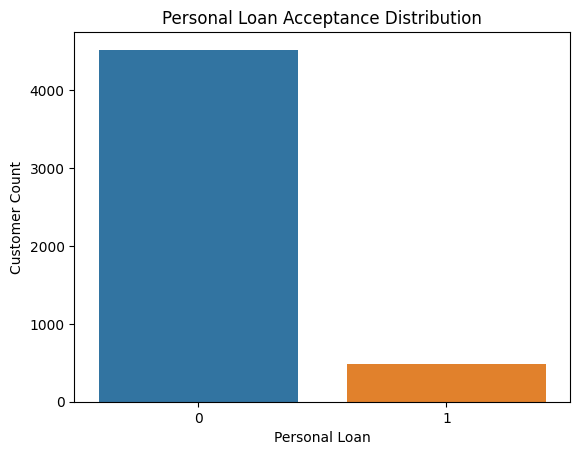

In [76]:
sns.countplot(x="Personal Loan", data=universal_bank_dataset)

plt.title("Personal Loan Acceptance Distribution")
plt.xlabel("Personal Loan")
plt.ylabel("Customer Count")

plt.show()

#### Data Preparation

In [77]:
universal_bank_dataset = universal_bank_dataset.drop(columns=["ID", "ZIP Code"])

In [78]:
X = universal_bank_dataset.drop(columns=["Personal Loan"])

y = universal_bank_dataset["Personal Loan"]

#### Model Building

In [79]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.20,random_state=42,stratify=y)

In [80]:
X_train.shape,X_test.shape

y_train.shape,y_test.shape

((4000,), (1000,))

In [94]:
svm_model = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC(kernel="rbf", C=1.0, gamma="scale",
                 class_weight="balanced", probability=True))
])

#### Model Training

In [95]:
svm_model.fit(X_train, y_train)

Pipeline(steps=[('scaler', StandardScaler()),
                ('svm', SVC(class_weight='balanced', probability=True))])

#### Model Evaluation

In [83]:
training_prediction = svm_model.predict(X_train)

In [84]:
training_accuracy = accuracy_score(y_train,training_prediction)

print("Training Accuracy:", training_accuracy)

Training Accuracy: 0.96625


In [85]:
testing_prediction = svm_model.predict(X_test)

In [86]:
testing_accuracy = accuracy_score(y_test,testing_prediction)

print("Testing Accuracy:", testing_accuracy)

Testing Accuracy: 0.955


In [87]:
precision = precision_score(y_test,testing_prediction,zero_division=0)

print("Precision:", precision)

Precision: 0.6888888888888889


In [88]:
recall = recall_score(y_test,testing_prediction,zero_division=0)

print("Recall:", recall)

Recall: 0.96875


In [89]:
f1 = f1_score(y_test,testing_prediction,zero_division=0)

print("F1 Score:", f1)

F1 Score: 0.8051948051948051


In [91]:
print(classification_report(y_test,testing_prediction))

              precision    recall  f1-score   support

           0       1.00      0.95      0.97       904
           1       0.69      0.97      0.81        96

    accuracy                           0.95      1000
   macro avg       0.84      0.96      0.89      1000
weighted avg       0.97      0.95      0.96      1000



In [52]:
confusion_matrix_result = confusion_matrix(y_test,testing_prediction)

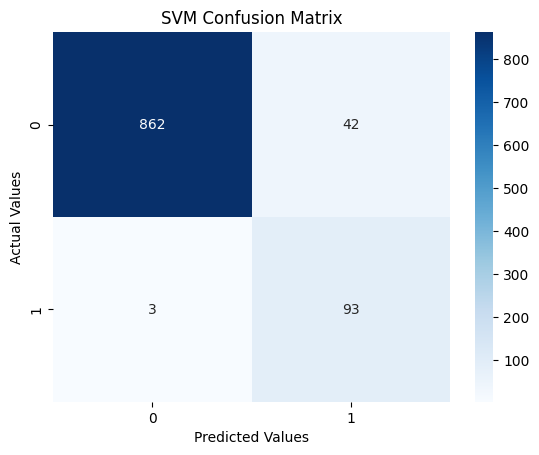

In [53]:
sns.heatmap(confusion_matrix_result,annot=True,fmt="d",cmap="Blues")

plt.title("SVM Confusion Matrix")
plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")

plt.show()

In [54]:
confusion_matrix_result = confusion_matrix(y_test,testing_prediction)

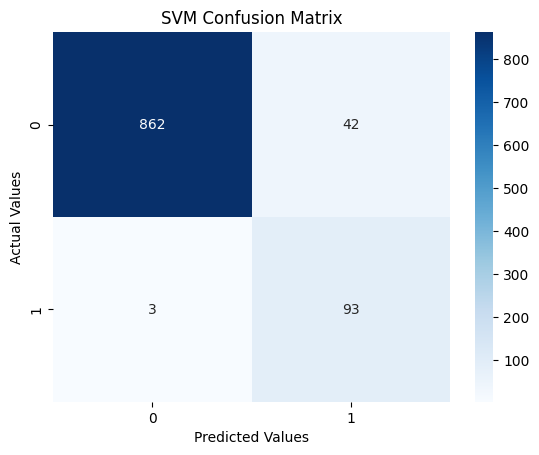

In [55]:
sns.heatmap(confusion_matrix_result,annot=True,fmt="d",cmap="Blues")

plt.title("SVM Confusion Matrix")
plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")

plt.show()

#### Model Testing

In [56]:
new_customer_data = pd.DataFrame({"Age": [40],"Experience": [15],"Income": [80],"Family": [3],"CCAvg": [2.5],"Education": [2],"Mortgage": [0],"Securities Account": [0],"CD Account": [1],"Online": [1],"CreditCard": [0]})

In [57]:
new_customer_prediction = svm_model.predict(new_customer_data)

In [64]:
if new_customer_prediction[0] == 1:

    print("Customer is likely to accept the Personal Loan")

else:

    print("Customer is unlikely to accept the Personal Loan")

Customer is likely to accept the Personal Loan


In [96]:
new_customer_probability = svm_model.predict_proba(new_customer_data)

print("Not Accepting Loan:", new_customer_probability[0][0])
print("Accepting Loan:", new_customer_probability[0][1])

Not Accepting Loan: 0.2681823789285543
Accepting Loan: 0.7318176210714457
